<a href="https://colab.research.google.com/github/mominanoor/Machine-Learning/blob/main/Concept_Drift_Detection_Malware_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Cell 1: Install aur dataset clone
!pip -q install optuna xgboost
import os
if not os.path.exists("/content/kronodroid"):
    !git clone --depth 1 https://github.com/aleguma/kronodroid.git /content/kronodroid
!ls -la /content/kronodroid/real_device

Cloning into '/content/kronodroid'...
remote: Enumerating objects: 10, done.
remote: Counting objects: 100% (10/10), done.
remote: Compressing objects: 100% (10/10), done.
remote: Total 10 (delta 0), reused 5 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (10/10), 24.50 MiB | 22.70 MiB/s, done.
total 13840
drwxr-xr-x 2 root root    4096 Oct 28 06:35 .
drwxr-xr-x 5 root root    4096 Oct 28 06:35 ..
-rw-r--r-- 1 root root 5848822 Oct 28 06:35 real_legitimate_v1.zip
-rw-r--r-- 1 root root 8312750 Oct 28 06:35 real_malware_v1.zip


In [2]:
# Cell 2: Imports aur config
import os, glob, zipfile, warnings, time, itertools
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import optuna
from joblib import Parallel, delayed
from scipy.spatial.distance import cdist
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, OneClassSVM
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)

# ------------------------- CONFIG -------------------------
PRESET   = "quick"          # "quick" | "medium" | "paper"
SEED     = 420
B, T     = 50, 30           # batch size, train samples per batch (test = 20)
MODELS   = ["MLP", "RF", "SVM", "XGB"]
N_JOBS   = -1               # parallel over batches
RESULTS  = "/content/results"
PRESETS = {
    "quick":  dict(N_TRIALS=5,   ONLY_SMALLEST_FD=True),   # 1 drift family x 4 controls
    "medium": dict(N_TRIALS=20,  ONLY_SMALLEST_FD=False),  # all 20 pairs
    "paper":  dict(N_TRIALS=100, ONLY_SMALLEST_FD=False),  # exact paper setting (very slow)
}
N_TRIALS         = PRESETS[PRESET]["N_TRIALS"]
ONLY_SMALLEST_FD = PRESETS[PRESET]["ONLY_SMALLEST_FD"]
os.makedirs(RESULTS, exist_ok=True)

# Drift-detector grids (Table 3 of the paper)
MK_CLUSTERS = [2, 4, 6, 8]
THRESHOLDS  = [round(x, 2) for x in np.arange(0.01, 0.61, 0.01)]
OC_NUS      = [round(x, 1) for x in np.arange(0.1, 1.0, 0.1)]
MMD_ALPHAS  = [round(x, 3) for x in np.arange(0.001, 0.1005, 0.001)]
print("PRESET:", PRESET, "| N_TRIALS:", N_TRIALS)

PRESET: quick | N_TRIALS: 5


In [3]:
# Cell 3: KronoDroid load aur preprocessing (corrected)
DATA_DIR = "/content/kronodroid_data"
os.makedirs(DATA_DIR, exist_ok=True)
CSV_PATH = f"{DATA_DIR}/real_malware_v1.csv"

if not os.path.exists(CSV_PATH):
    with zipfile.ZipFile("/content/kronodroid/real_device/real_malware_v1.zip") as zf:
        zf.extractall(DATA_DIR)
print("Using:", CSV_PATH)

df = pd.read_csv(CSV_PATH, low_memory=False)
FAM, DATE = "MalFamily", "HighestModDate"

# valid timestamps only: MM/DD/YYYY, years 2000..2025
df["_date"] = pd.to_datetime(df[DATE], format="%m/%d/%Y", errors="coerce")
df = df[df["_date"].dt.year.between(2000, 2025)]

# numeric features only (paper: 470 dims after removing text columns)
drop_kw = ["moddate", "detection", "scanner", "malware", "family", "package", "sha256", "_date"]
feat_cols = [c for c in df.columns
             if not any(k in c.lower() for k in drop_kw) and pd.api.types.is_numeric_dtype(df[c])]
print("Feature dimension:", len(feat_cols), "(paper: 470)")

# five largest families
top5 = df[FAM].value_counts().head(5).index.tolist()
df = df[df[FAM].isin(top5)].copy()
scaler = StandardScaler().fit(df[feat_cols].fillna(0).values)

fam_data = {}
summary = []
for f in top5:
    sub = df[df[FAM] == f].sort_values("_date", kind="stable")
    X = scaler.transform(sub[feat_cols].fillna(0).values)
    N = len(X) // B
    fam_data[f] = X[:N * B]
    summary.append([f, len(sub), N, sub["_date"].min().date(), sub["_date"].max().date()])
print(pd.DataFrame(summary, columns=["Family", "Samples", "Batches", "Earliest", "Latest"]))

def batches_of(f):
    X = fam_data[f]
    return X.reshape(len(X) // B, B, -1)

fams = sorted(top5, key=lambda f: len(fam_data[f]))
FD_LIST = [fams[0]] if ONLY_SMALLEST_FD else top5
PAIRS = [(fd, fc) for fd in FD_LIST for fc in top5 if fc != fd]
print("Pairs:", len(PAIRS), PAIRS[:4], "...")

Using: /content/kronodroid_data/real_malware_v1.csv
Feature dimension: 467 (paper: 470)
            Family  Samples  Batches    Earliest      Latest
0  Airpush/StopSMS     7760      155  2008-02-29  2018-06-15
1           SMSreg     4989       99  2008-02-29  2020-11-09
2            Malap     4018       80  2008-02-29  2020-11-11
3            Boxer     3597       71  2005-01-01  2018-06-15
4            Agent     2826       56  2008-02-28  2020-07-17
Pairs: 4 [('Agent', 'Airpush/StopSMS'), ('Agent', 'SMSreg'), ('Agent', 'Malap'), ('Agent', 'Boxer')] ...


In [4]:
# Cell 4: Drift detectors (MK-Means, OCSVM, MMD)
# ---------- MK-Means (silhouette) ----------
def mk_silhouettes(Bt, k):
    s = []
    for j in range(len(Bt) - 1):
        Z = np.vstack([Bt[j], Bt[j + 1]])
        lab = MiniBatchKMeans(n_clusters=k, random_state=SEED, n_init=3, batch_size=256).fit_predict(Z)
        s.append(silhouette_score(Z, lab) if len(set(lab)) > 1 else 0.0)
    return np.array(s)

def mk_drift_points(s, thr):
    d = np.abs(np.diff(s))                 # |s_{j+1}-s_j| -> drift at batch j+1
    return [int(j + 1) for j in np.where(d > thr)[0]]

# ---------- OCSVM (outlier/inlier ratio) ----------
def ocsvm_ratio(model, Bi):
    pred = model.predict(Bi)
    n_out = (pred == -1).sum(); n_in = (pred == 1).sum()
    return n_out / max(n_in, 1)

def ocsvm_drift_points(Bt, nu, thr):
    N = len(Bt)
    model = OneClassSVM(nu=nu, kernel="rbf", gamma="scale").fit(Bt[0])
    r_ref = ocsvm_ratio(model, Bt[0])
    pts = []
    for i in range(1, N):
        r_i = ocsvm_ratio(model, Bt[i])
        if abs(r_i - r_ref) > thr:
            pts.append(i)
            model = OneClassSVM(nu=nu, kernel="rbf", gamma="scale").fit(Bt[i])
            r_ref = ocsvm_ratio(model, Bt[i])
    return pts

# ---------- MMD two-sample permutation test (Gaussian kernel) ----------
def mmd_pvalue(X, Y, n_perm=100, rng=None):
    rng = rng or np.random.default_rng(SEED)
    Z = np.vstack([X, Y]); n, m = len(X), len(Y)
    D2 = cdist(Z, Z, "sqeuclidean")
    sigma = np.median(D2[:n, n:]) + 1e-12
    K = np.exp(-D2 / sigma)
    def stat(Kp):
        Kxx, Kyy, Kxy = Kp[:n, :n], Kp[n:, n:], Kp[:n, n:]
        return ((Kxx.sum() - np.trace(Kxx)) / (n * (n - 1))
                - 2 * Kxy.mean()
                + (Kyy.sum() - np.trace(Kyy)) / (m * (m - 1)))
    obs = stat(K)
    cnt = 0
    for _ in range(n_perm):
        p = rng.permutation(n + m)
        if stat(K[np.ix_(p, p)]) >= obs: cnt += 1
    return (cnt + 1) / (n_perm + 1)

def compute_drift_sets(fd):
    Bt = batches_of(fd); N = len(Bt)
    out = {"mk-means": {}, "ocsvm": {}, "mmd": {}}
    t0 = time.time()
    # MK-Means
    for k in MK_CLUSTERS:
        s = mk_silhouettes(Bt, k)
        for thr in THRESHOLDS:
            out["mk-means"][(k, thr)] = mk_drift_points(s, thr)
    # MMD (p-values computed once, alpha swept)
    rng = np.random.default_rng(SEED)
    pv = np.array([mmd_pvalue(Bt[i - 1], Bt[i], rng=rng) for i in range(1, N)])
    for a in MMD_ALPHAS:
        out["mmd"][a] = [int(i + 1) for i in np.where(pv <= a)[0]]
    # OCSVM (parallel over nu)
    def run_nu(nu):
        return {(nu, thr): ocsvm_drift_points(Bt, nu, thr) for thr in THRESHOLDS}
    for d in Parallel(n_jobs=N_JOBS)(delayed(run_nu)(nu) for nu in OC_NUS):
        out["ocsvm"].update(d)
    print(f"[{fd}] N={N} batches, drift detection done in {time.time()-t0:.0f}s")
    return out, {"mk-means": N - 2, "ocsvm": N - 1, "mmd": N - 1}

DRIFT, POSSIBLE = {}, {}
for fd in FD_LIST:
    DRIFT[fd], POSSIBLE[fd] = compute_drift_sets(fd)

[Agent] N=56 batches, drift detection done in 58s


In [5]:
# Cell 5: Models ki Optuna (TPE) tuning, har batch par
def make_model(L, trial):
    if L == "SVM":
        return SVC(C=trial.suggest_float("C", np.exp(-4), np.exp(4), log=True), kernel="rbf", random_state=SEED)
    if L == "RF":
        return RandomForestClassifier(n_estimators=trial.suggest_int("n_estimators", 10, 500),
                                      max_depth=trial.suggest_int("max_depth", 5, 100),
                                      random_state=SEED, n_jobs=1)
    if L == "XGB":
        return XGBClassifier(n_estimators=trial.suggest_int("n_estimators", 10, 300),
                             max_depth=trial.suggest_int("max_depth", 5, 15),
                             learning_rate=trial.suggest_categorical("lr", [0.01, 0.05, 0.1, 0.2, 0.3]),
                             random_state=SEED, n_jobs=1, verbosity=0, eval_metric="logloss")
    if L == "MLP":
        return MLPClassifier(hidden_layer_sizes=(trial.suggest_int("n_units", 8, 256),),
                             activation=trial.suggest_categorical("activation", ["relu", "tanh", "logistic"]),
                             solver=trial.suggest_categorical("solver", ["adam", "sgd"]),
                             max_iter=300, random_state=SEED)

def train_batch(L, i, Bt, Xc, n_trials, seed=SEED):
    import warnings, optuna
    warnings.filterwarnings("ignore"); optuna.logging.set_verbosity(optuna.logging.WARNING)
    Bi = Bt[i]
    Xtr = np.vstack([Bi[:T], Xc[:T]]);   ytr = np.r_[np.ones(T), np.zeros(T)]
    Xte = np.vstack([Bi[T:], Xc[T:B]]);  yte = np.r_[np.ones(B - T), np.zeros(B - T)]
    best = {"acc": -1.0, "model": None}
    def objective(trial):
        m = make_model(L, trial); m.fit(Xtr, ytr)
        acc = float((m.predict(Xte) == yte).mean())
        if acc > best["acc"]: best.update(acc=acc, model=m)
        return acc
    def stop_cb(study, trial):
        if trial.value is not None and trial.value >= 1.0: study.stop()   # ideal separation
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=seed))
    study.optimize(objective, n_trials=n_trials, callbacks=[stop_cb])
    model = best["model"]
    Xall = np.vstack([np.vstack([Bt[k][T:], Xc[T:B]]) for k in range(len(Bt))])
    yall = np.tile(yte, len(Bt))
    return (model.predict(Xall) == yall).reshape(len(Bt), -1).sum(1)   # correct counts on every batch's test set

CMAT = {}
t0 = time.time()
safe = lambda s: s.replace("/", "-").replace(" ", "_")

for (fd, fc) in PAIRS:
    Bt, Xc = batches_of(fd), fam_data[fc][:B]
    for L in MODELS:
        path = f"{RESULTS}/C_{safe(fd)}_{safe(fc)}_{L}_t{N_TRIALS}.npy"
        if os.path.exists(path):
            CMAT[(fd, fc, L)] = np.load(path)
            continue
        rows = Parallel(n_jobs=N_JOBS)(delayed(train_batch)(L, i, Bt, Xc, N_TRIALS) for i in range(len(Bt)))
        CMAT[(fd, fc, L)] = np.array(rows)
        np.save(path, CMAT[(fd, fc, L)])
        print(f"({fd},{fc},{L}) done | elapsed {(time.time()-t0)/60:.1f} min")

(Agent,Airpush/StopSMS,MLP) done | elapsed 0.5 min
(Agent,Airpush/StopSMS,RF) done | elapsed 1.4 min
(Agent,Airpush/StopSMS,SVM) done | elapsed 1.4 min
(Agent,Airpush/StopSMS,XGB) done | elapsed 1.5 min
(Agent,SMSreg,MLP) done | elapsed 2.1 min
(Agent,SMSreg,RF) done | elapsed 3.4 min
(Agent,SMSreg,SVM) done | elapsed 3.5 min
(Agent,SMSreg,XGB) done | elapsed 3.6 min
(Agent,Malap,MLP) done | elapsed 4.3 min
(Agent,Malap,RF) done | elapsed 5.6 min
(Agent,Malap,SVM) done | elapsed 5.6 min
(Agent,Malap,XGB) done | elapsed 5.7 min
(Agent,Boxer,MLP) done | elapsed 6.0 min
(Agent,Boxer,RF) done | elapsed 6.4 min
(Agent,Boxer,SVM) done | elapsed 6.4 min
(Agent,Boxer,XGB) done | elapsed 6.4 min


In [6]:
# Cell 6: Static / Periodic / Drift-aware accuracy aur efficiency
TEST_PER_BATCH = 2 * (B - T)

def acc_static(C):   return C[0, :].sum() / (C.shape[1] * TEST_PER_BATCH)
def acc_periodic(C): return np.trace(C) / (C.shape[1] * TEST_PER_BATCH)
def acc_drift(C, pts):
    N = C.shape[1]; arr = np.zeros(N, int)
    for p in pts: arr[p] = p                       # retrain at drift batch p
    idx = np.maximum.accumulate(arr)               # model in use at batch k
    return C[idx, np.arange(N)].sum() / (N * TEST_PER_BATCH)

recs, base = [], []
for (fd, fc) in PAIRS:
    for L in MODELS:
        C = CMAT[(fd, fc, L)]
        As, Ap = acc_static(C), acc_periodic(C)
        base.append(dict(Fd=fd, Fc=fc, L=L, static=As, periodic=Ap))
        for R, sets in DRIFT[fd].items():
            for om, pts in sets.items():
                A = acc_drift(C, pts)
                E = 1 - len(pts) / POSSIBLE[fd][R]
                recs.append(dict(Fd=fd, Fc=fc, L=L, R=R, omega=str(om), A=A, E=E, D=A - As))
rec = pd.DataFrame(recs); base = pd.DataFrame(base)
rec.to_csv(f"{RESULTS}/drift_aware_all_points.csv", index=False)
base.to_csv(f"{RESULTS}/static_periodic.csv", index=False)
print(base.groupby("L")[["static", "periodic"]].mean().round(4))

     static  periodic
L                    
MLP  0.7927    0.9223
RF   0.8698    0.9121
SVM  0.8282    0.9202
XGB  0.8779    0.9087


In [7]:
# Cell 7: Pareto Front analysis
def pareto_mask(P):                       # maximise both objectives
    mask = np.ones(len(P), bool)
    for i in range(len(P)):
        dom = (P >= P[i]).all(1) & (P > P[i]).any(1)
        if dom.any(): mask[i] = False
    return mask

def pick_median(P):                       # P columns: (DeltaAcc, Efficiency)
    lo, hi = P[P[:, 0].argmin()], P[P[:, 0].argmax()]
    xa, ya = (lo[0] + hi[0]) / 2, (lo[1] + hi[1]) / 2
    nrm = np.hypot(xa, ya)
    if nrm == 0: return 0
    dist = np.abs(ya * P[:, 0] - xa * P[:, 1]) / nrm       # distance to line y=(ya/xa)x
    return int(dist.argmin())

def summarize(rec):
    rows = []
    for (L, R), g in rec.groupby(["L", "R"]):
        o = dict(L=L, R=R, A_all=g.A.mean(), E_all=g.E.mean())
        w = g.groupby("omega")[["A", "D", "E"]].mean()
        m = pareto_mask(w[["D", "E"]].values)
        o["A_x"], o["E_x"] = w.A[m].mean(), w.E[m].mean()
        ay, ey, am, em = [], [], [], []
        for _, h in g.groupby(["Fd", "Fc"]):
            hp = h[pareto_mask(h[["D", "E"]].values)]
            ay.append(hp.A.mean()); ey.append(hp.E.mean())
            j = pick_median(hp[["D", "E"]].values)
            am.append(hp.A.iloc[j]); em.append(hp.E.iloc[j])
        o.update(A_y=np.mean(ay), E_y=np.mean(ey), A_m=np.mean(am), E_m=np.mean(em))
        rows.append(o)
    return pd.DataFrame(rows)

S = summarize(rec)
S = S.merge(base.groupby("L")[["static", "periodic"]].mean().reset_index(), on="L")
S.to_csv(f"{RESULTS}/summary_per_model_detector.csv", index=False)
print(S.round(4).to_string(index=False))

print("\n=== Detector comparison (mean over all models) ===")
cmp_ = S.groupby("R")[["A_all", "A_x", "A_y", "A_m", "E_all", "E_x", "E_y", "E_m"]].mean().round(4)
print(cmp_)
cmp_.to_csv(f"{RESULTS}/detector_comparison.csv")

  L        R  A_all  E_all    A_x    E_x    A_y    E_y    A_m    E_m  static  periodic
MLP mk-means 0.8537 0.7329 0.8438 0.8262 0.8430 0.8627 0.8858 0.7639  0.7927    0.9223
MLP      mmd 0.9040 0.3613 0.9034 0.3630 0.9030 0.3767 0.9050 0.4364  0.7927    0.9223
MLP    ocsvm 0.8976 0.3091 0.8754 0.5119 0.8703 0.5793 0.8898 0.5727  0.7927    0.9223
 RF mk-means 0.8752 0.7329 0.8787 0.8977 0.8797 0.9455 0.8941 0.9491  0.8698    0.9121
 RF      mmd 0.9049 0.3613 0.9035 0.3913 0.9069 0.6968 0.9057 0.7182  0.8698    0.9121
 RF    ocsvm 0.9015 0.3091 0.8929 0.5529 0.8982 0.6935 0.9033 0.6682  0.8698    0.9121
SVM mk-means 0.8684 0.7329 0.8486 0.8836 0.8541 0.9547 0.8760 0.9259  0.8282    0.9202
SVM      mmd 0.9076 0.3613 0.8932 0.5032 0.8984 0.5933 0.9087 0.5773  0.8282    0.9202
SVM    ocsvm 0.8982 0.3091 0.8714 0.6091 0.8762 0.6695 0.8878 0.7409  0.8282    0.9202
XGB mk-means 0.8737 0.7329 0.8833 0.8600 0.8859 0.9545 0.9012 0.9120  0.8779    0.9087
XGB      mmd 0.8988 0.3613 0.8999 0.3647 0.

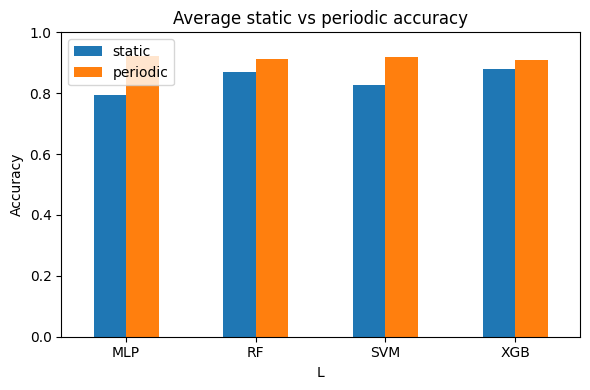

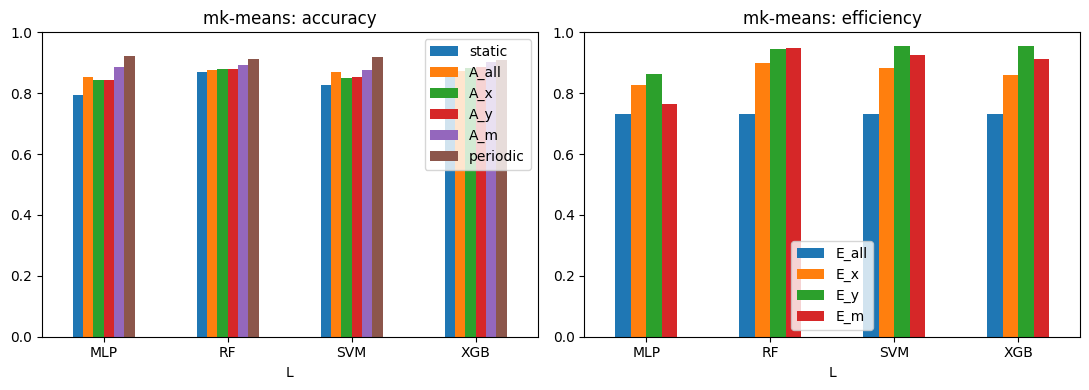

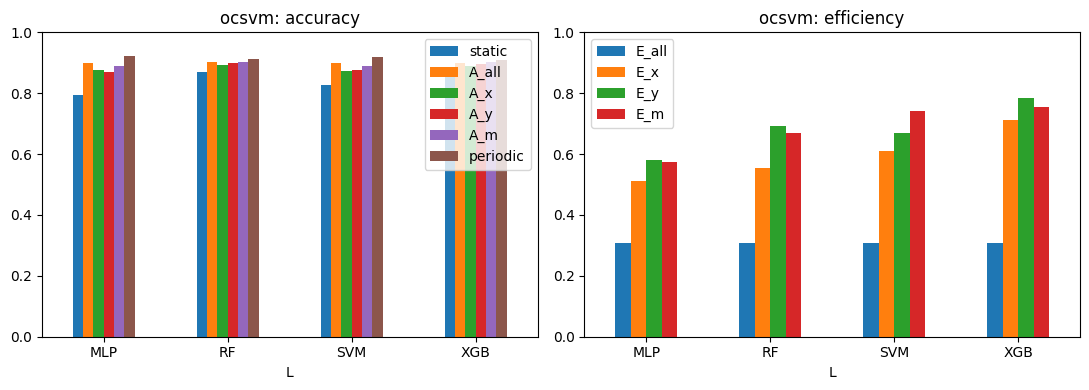

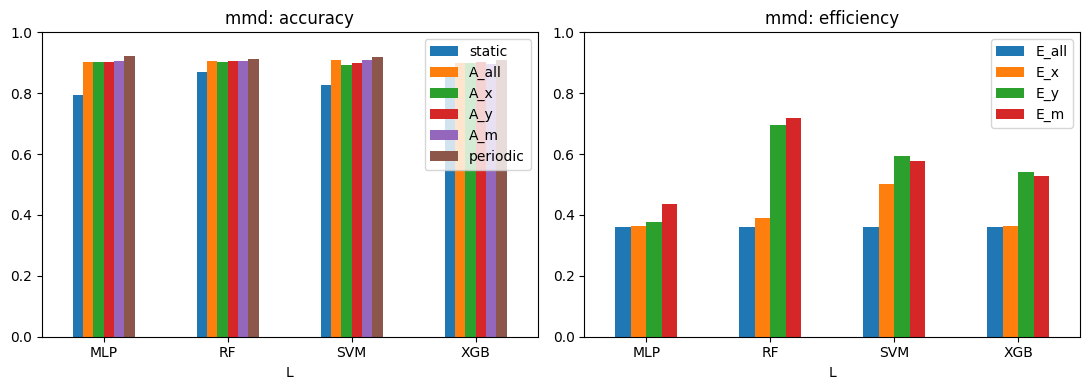

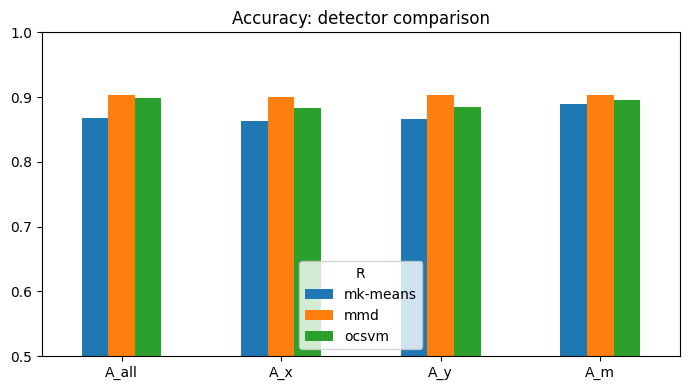

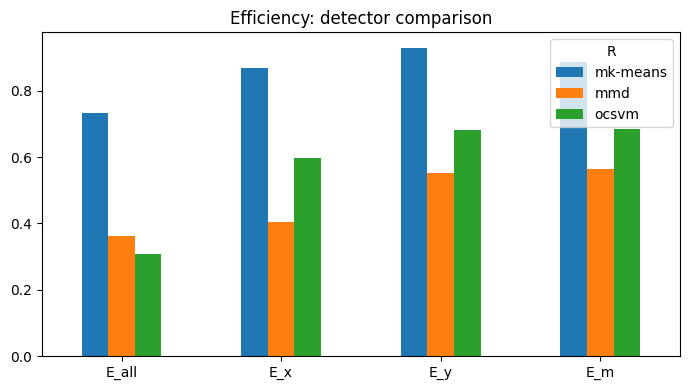

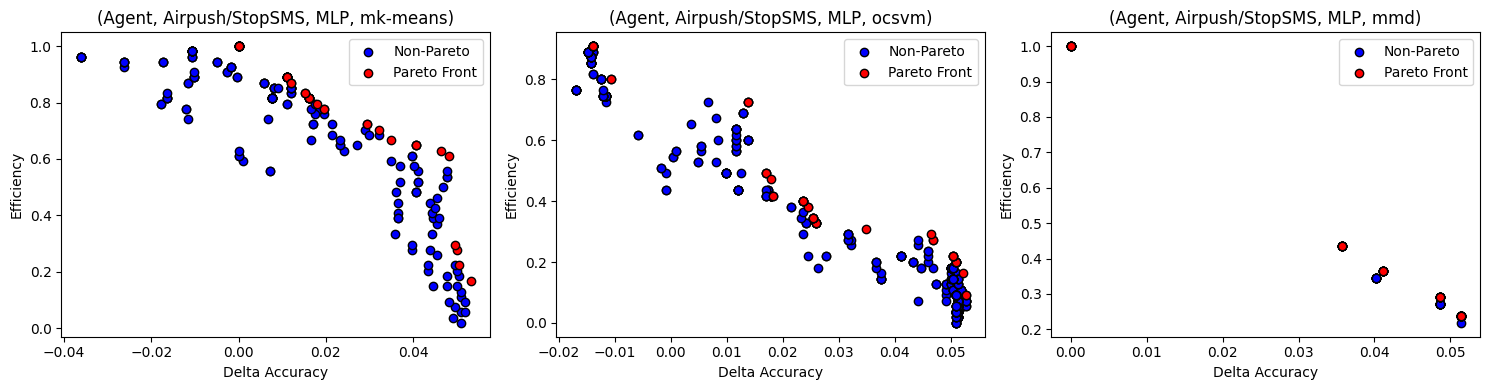

In [8]:
#Cell 8: Plots
colors = {"ocsvm": "tab:orange", "mk-means": "tab:olive", "mmd": "tab:purple"}

# (a) static vs periodic
bm = base.groupby("L")[["static", "periodic"]].mean().reindex(MODELS)
bm.plot.bar(figsize=(6, 4), rot=0, ylim=(0, 1)); plt.title("Average static vs periodic accuracy")
plt.ylabel("Accuracy"); plt.tight_layout(); plt.savefig(f"{RESULTS}/fig_static_periodic.png", dpi=150); plt.show()

# (b) per-detector accuracy / efficiency per model (median Pareto point)
for R in ["mk-means", "ocsvm", "mmd"]:
    s = S[S.R == R].set_index("L").reindex(MODELS)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    s[["static", "A_all", "A_x", "A_y", "A_m", "periodic"]].plot.bar(ax=ax[0], rot=0, ylim=(0, 1)); ax[0].set_title(f"{R}: accuracy")
    s[["E_all", "E_x", "E_y", "E_m"]].plot.bar(ax=ax[1], rot=0, ylim=(0, 1)); ax[1].set_title(f"{R}: efficiency")
    plt.tight_layout(); plt.savefig(f"{RESULTS}/fig_{R}.png", dpi=150); plt.show()

# (c) detector comparison
cmp_[["A_all", "A_x", "A_y", "A_m"]].T.plot.bar(figsize=(7, 4), rot=0, ylim=(0.5, 1)); plt.title("Accuracy: detector comparison")
plt.tight_layout(); plt.savefig(f"{RESULTS}/fig_cmp_acc.png", dpi=150); plt.show()
cmp_[["E_all", "E_x", "E_y", "E_m"]].T.plot.bar(figsize=(7, 4), rot=0); plt.title("Efficiency: detector comparison")
plt.tight_layout(); plt.savefig(f"{RESULTS}/fig_cmp_eff.png", dpi=150); plt.show()

# (d) Pareto-front example (first pair, MLP)
fd, fc = PAIRS[0]
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, R in zip(ax, ["mk-means", "ocsvm", "mmd"]):
    h = rec[(rec.Fd == fd) & (rec.Fc == fc) & (rec.L == "MLP") & (rec.R == R)]
    m = pareto_mask(h[["D", "E"]].values)
    a.scatter(h.D[~m], h.E[~m], c="blue", edgecolor="k", label="Non-Pareto")
    a.scatter(h.D[m], h.E[m], c="red", edgecolor="k", label="Pareto Front")
    a.set_title(f"({fd}, {fc}, MLP, {R})"); a.set_xlabel("Delta Accuracy"); a.set_ylabel("Efficiency"); a.legend()
plt.tight_layout(); plt.savefig(f"{RESULTS}/fig_pareto_example.png", dpi=150); plt.show()

In [9]:
# Cell 9: Results download (optional)
!cd /content && zip -qr results.zip results
try:
    from google.colab import files
    files.download("/content/results.zip")
except Exception as e:
    print("Download manually from /content/results.zip", e)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>